# Sumas de prefijos

Se precalculan las sumas acumuladas $P_0 = 0$, $P_{i+1} = P_i + a_i$ en $O(n)$, y la suma de cualquier tramo sale de restar dos prefijos en $O(1)$:

$$\sum_{k=i}^{j-1} a_k = P_j - P_i$$

En una matriz se hace lo mismo con rectángulos e inclusión-exclusión. La operación inversa es el array de diferencias $d_i = a_i - a_{i-1}$: sumar $v$ a todo un tramo solo cambia dos valores de $d$, y los prefijos de $d$ reconstruyen $a$.

## 1. Sumas de rango en O(1)

Precalcular los prefijos con `itertools.accumulate` y responder consultas `suma_rango(p, i, j)` de $a_i + \dots + a_{j-1}$ en $O(1)$. Comprobar con `sum` y comparar tiempos con muchas consultas.

In [1]:
import random
import timeit
from itertools import accumulate

def prefijos(a):
    return list(accumulate(a, initial=0))

def suma_rango(p, i, j):
    return p[j] - p[i]

p = prefijos([3, 1, 4, 1, 5])
print(p, suma_rango(p, 1, 4))

random.seed(1)
a = [random.randint(-100, 100) for _ in range(10_000)]
p = prefijos(a)
consultas = [sorted(random.sample(range(len(a) + 1), 2)) for _ in range(2_000)]
assert all(suma_rango(p, i, j) == sum(a[i:j]) for i, j in consultas)
print(f"prefijos {timeit.timeit(lambda: [suma_rango(p, i, j) for i, j in consultas], number=1):.4f} s")
print(f"sum      {timeit.timeit(lambda: [sum(a[i:j]) for i, j in consultas], number=1):.4f} s")

[0, 3, 4, 8, 9, 14] 6
prefijos 0.0002 s
sum      0.0904 s


## 2. Subarrays con suma k

Contar los subarrays contiguos que suman $k$, también con números negativos (donde la ventana deslizante no sirve). Un tramo $[i, j)$ suma $k$ si $P_j - P_i = k$: recorrer los prefijos guardando en un diccionario cuántas veces ha salido cada valor y sumar las apariciones de $P_j - k$. Cuesta $O(n)$ frente a $O(n^2)$. Comprobar contra la fuerza bruta.

In [2]:
from collections import defaultdict

def subarrays_con_suma(a, k):
    vistos, suma, total = defaultdict(int), 0, 0
    vistos[0] = 1
    for x in a:
        suma += x
        total += vistos[suma - k]
        vistos[suma] += 1
    return total

def subarrays_con_suma_bruta(a, k):
    return sum(sum(a[i:j]) == k for i in range(len(a)) for j in range(i + 1, len(a) + 1))

for _ in range(1000):
    a = [random.randint(-3, 3) for _ in range(random.randint(0, 15))]
    k = random.randint(-4, 4)
    assert subarrays_con_suma(a, k) == subarrays_con_suma_bruta(a, k)
print(subarrays_con_suma([1, 1, 1], 2), subarrays_con_suma([3, 4, 7, 2, -3, 1, 4, 2], 7))

2 4


## 3. Sumas de prefijos 2D

En una matriz $m$, sea $P_{i,j}$ la suma del rectángulo de filas $[0, i)$ y columnas $[0, j)$:

$$P_{i+1,j+1} = m_{i,j} + P_{i,j+1} + P_{i+1,j} - P_{i,j}$$

Cualquier submatriz se suma con cuatro valores por inclusión-exclusión. Comprobarlo con NumPy y buscar la submatriz $3 \times 3$ de suma máxima.

In [3]:
import numpy as np

def prefijos_2d(m):
    filas, columnas = len(m), len(m[0])
    p = [[0] * (columnas + 1) for _ in range(filas + 1)]
    for i in range(filas):
        for j in range(columnas):
            p[i + 1][j + 1] = m[i][j] + p[i][j + 1] + p[i + 1][j] - p[i][j]
    return p

def suma_rectangulo(p, f1, c1, f2, c2):
    # filas f1..f2-1, columnas c1..c2-1
    return p[f2][c2] - p[f1][c2] - p[f2][c1] + p[f1][c1]

rng = np.random.default_rng(3)
m = rng.integers(-9, 10, size=(8, 10))
p = prefijos_2d(m.tolist())
assert np.array_equal(np.array(p)[1:, 1:], m.cumsum(axis=0).cumsum(axis=1))
for _ in range(500):
    f1, f2 = sorted(rng.integers(0, 9, size=2))
    c1, c2 = sorted(rng.integers(0, 11, size=2))
    assert suma_rectangulo(p, f1, c1, f2, c2) == m[f1:f2, c1:c2].sum()

k = 3
suma, f, c = max((suma_rectangulo(p, i, j, i + k, j + k), i, j) for i in range(8 - k + 1) for j in range(10 - k + 1))
print(m)
print(f"Submatriz {k}×{k} de suma máxima ({suma}) en la fila {f}, columna {c}:")
print(m[f:f + k, c:c + k])

[[ 6 -8 -6 -5 -6  6  7  2 -9 -8]
 [-3 -1  2  0 -4 -6  4  4 -9 -7]
 [-1 -2  7  0 -2 -1  3  2 -6  5]
 [ 5  9  5 -4 -3  3  3  4  7 -4]
 [ 8 -9 -8  9  8 -4 -7 -4 -9  7]
 [ 3  2 -5 -1 -6  5  0 -9 -5  4]
 [ 0 -2 -5 -8  2  3  0  8  8 -6]
 [ 2  2 -5 -4  0  5 -4  4  3 -5]]
Submatriz 3×3 de suma máxima (21) en la fila 1, columna 0:
[[-3 -1  2]
 [-1 -2  7]
 [ 5  9  5]]


## 4. Array de diferencias

Aplicar muchas actualizaciones "sumar $v$ a las posiciones $[i, j)$" en $O(1)$ cada una: sumar $v$ en $d_i$ y restarlo en $d_j$; al final, los prefijos de $d$ dan el array. Cuesta $O(n + q)$ frente a $O(n \cdot q)$. Comprobarlo con fuerza bruta y usarlo para dibujar cuántas habitaciones de un hotel están ocupadas cada noche a partir de las reservas (entrada, salida).

[1, 2, 2, 3, 2, 2, 1, 1, 2, 1, 3, 2, 1, 1, 0]


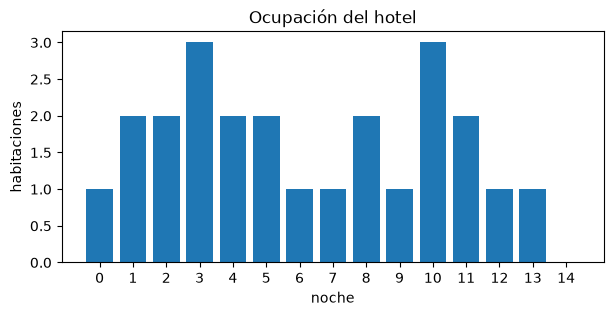

In [4]:
import matplotlib.pyplot as plt

def aplica_rangos(n, actualizaciones):
    d = [0] * (n + 1)
    for i, j, v in actualizaciones:
        d[i] += v
        d[j] -= v
    return list(accumulate(d[:n]))

def aplica_rangos_bruto(n, actualizaciones):
    a = [0] * n
    for i, j, v in actualizaciones:
        for x in range(i, j):
            a[x] += v
    return a

for _ in range(500):
    n = random.randint(1, 20)
    actualizaciones = [(*sorted(random.sample(range(n + 1), 2)), random.randint(-5, 5)) for _ in range(random.randint(0, 10))]
    assert aplica_rangos(n, actualizaciones) == aplica_rangos_bruto(n, actualizaciones)

reservas = [(1, 4), (2, 6), (3, 5), (5, 9), (8, 12), (10, 11), (10, 14), (0, 2)]
ocupacion = aplica_rangos(15, [(entrada, salida, 1) for entrada, salida in reservas])
print(ocupacion)

fig, eje = plt.subplots(figsize=(7, 3))
eje.bar(range(15), ocupacion, color="tab:blue")
eje.set_xticks(range(15))
eje.set_xlabel("noche")
eje.set_ylabel("habitaciones")
eje.set_title("Ocupación del hotel")
plt.show()

## 5. Índices de equilibrio

Encontrar las posiciones $i$ en las que la suma de los elementos a la izquierda es igual a la de los de la derecha. Con el total $T$ y el prefijo $P_i$, la parte derecha vale $T - P_i - a_i$, así que basta una pasada. Comprobarlo con fuerza bruta.

In [5]:
def equilibrios(a):
    total, izquierda, resultado = sum(a), 0, []
    for i, x in enumerate(a):
        if izquierda == total - izquierda - x:
            resultado.append(i)
        izquierda += x
    return resultado

for _ in range(1000):
    a = [random.randint(-3, 3) for _ in range(random.randint(0, 10))]
    assert equilibrios(a) == [i for i in range(len(a)) if sum(a[:i]) == sum(a[i + 1:])]
print(equilibrios([1, 7, 3, 6, 5, 6]), equilibrios([2, 1, -1]), equilibrios([1, 2, 3]))

[3] [0] []
